# 07 — Model data & operasi (Bab 4.2)

**"Model data" di sini ≠ model machine learning.** Model data = cara data **disusun**: entitas apa saja, kunci apa yang menghubungkannya, format penyimpanannya, dan **operasi** apa yang cocok untuk tiap jenis data. (Model ML = Assignment 2.)

Tugas no. 8: *"Pilih model data dan operasi-operasi yang sesuai dengan karakteristik masing-masing data."*

| Data | Karakteristik | Model data yang dipilih | Disimpan sebagai | Operasi utama |
|---|---|---|---|---|
| Metadata (CSV) | Structured, skema tetap, 238 ribu baris | **Relasional / tabular** (entitas Event, Station, Trace) | Parquet kolumnar, partisi `dataset` | filter, groupBy/agregasi, join, window |
| Waveform (HDF5) | Unstructured, array numerik besar (45 ribu angka/trace), ±85 GB | **Array / wide-column**: 1 baris per trace, kolom array `e,n,z` | Parquet (nested `array<double>`), partisi `dataset` | operasi array (slice, transform, agregasi elemen), join ke metadata |
| Relasi event ↔ stasiun | Jaringan: 1 event direkam banyak stasiun, 1 stasiun merekam banyak event | **Graph** (node = event & stasiun, edge = rekaman) | Diturunkan dari metadata (DataFrame vertices + edges) | degree, konektivitas (A2: GraphFrames) |
| Lineage / laporan kualitas | Semi-structured, key-value | **Dokumen (JSON)** | `.jsonl` / `.json` di `_lineage/`, `quality/` | baca per dokumen |

Semua model memakai **schema-on-read** di data lake: raw disimpan apa adanya, struktur diterapkan saat dibaca/diproses Spark.

In [1]:
import sys, os, time
sys.path.insert(0, os.path.abspath('../src'))
from common import *
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pyspark.sql import functions as F, Window
pd.set_option('display.width', 200, 'display.max_columns', 30)
spark = spark_session('07_model')
meta = spark.read.parquet(f'{HDFS}{PROCESSED}/metadata')
wf = spark.read.parquet(f'{HDFS}{PROCESSED}/waveforms')
print('metadata :', meta.count(), 'baris,', len(meta.columns), 'kolom')
print('waveforms:', wf.count(), 'baris, dataset =', sorted(r.dataset for r in wf.select('dataset').distinct().collect()))
timings = []
def timed(name, kind, fn):
    t = time.time(); out = fn(); dt = time.time() - t
    timings.append({'operation': name, 'data': kind, 'seconds': round(dt, 2)}); print(f'[{dt:.2f} s] {name}')
    return out

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/09/23 23:07:33 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/09/23 23:07:33 WARN SparkConf: Note that spark.local.dir will be overridden by the value set by the cluster manager (via SPARK_LOCAL_DIRS in mesos/standalone/kubernetes and LOCAL_DIRS in YARN).


metadata : 237978 baris, 49 kolom


waveforms: 237978 baris, dataset = ['comcat', 'exotic', 'noise']


## 1. Model logis: entitas & relasi

Tabel metadata bersih berisi 1 baris per **rekaman (trace)**. Di dalamnya sebenarnya ada 3 entitas yang "tercampur" (denormalisasi):

```
EVENT (event_id)                STATION (network, station, location, channel)
  origin_time, lat, lon,          lat, lon, elevation
  depth, magnitude, label
        │ 1                              │ 1
        │                                │
        └──────────── N  TRACE  N ───────┘
                    (dataset, trace_name)  ← kunci
                    start_time, P/S pick, SNR, flag kualitas, label
                         │ 1
                         │ 1
                    WAVEFORM (dataset, trace_name)
                    e[], n[], z[]  (15001 / 18001 angka)
```
- Noise tidak punya EVENT (`event_id` NULL) → relasi EVENT–TRACE opsional.
- Kita **sengaja tetap menyimpan tabel lebar** (denormalized). Di data lake analitik, join berulang itu mahal, sedangkan Parquet kolumnar membuat kolom yang tidak dipakai tidak ikut dibaca. Tabel Event & Station diturunkan saat dibutuhkan (di bawah).
- WAVEFORM dipisah dari metadata karena ukurannya ±300.000× lebih besar per baris. Query metadata tidak boleh ikut membaca array.

### Cek: apakah entitas itu konsisten? (functional dependency)
Kalau `event_id` benar-benar kunci Event, setiap `event_id` harus punya tepat 1 waktu, lokasi, dan label.

In [2]:
ev_cols = ['source_origin_time', 'source_latitude_deg', 'source_longitude_deg', 'source_depth_km', 'preferred_source_magnitude', 'label']
fd_ev = meta.filter('event_id IS NOT NULL').groupBy('dataset', 'event_id').agg(*[F.countDistinct(c).alias(c) for c in ev_cols])
viol_ev = {c: fd_ev.filter(F.col(c) > 1).count() for c in ev_cols}
st_key = ['station_network_code', 'station_code', 'station_location_code', 'station_channel_code']
fd_st = meta.groupBy(st_key).agg(*[F.countDistinct(c).alias(c) for c in ['station_latitude_deg', 'station_longitude_deg', 'station_elevation_m']])
viol_st = {c: fd_st.filter(F.col(c) > 1).count() for c in ['station_latitude_deg', 'station_longitude_deg', 'station_elevation_m']}
print('event_id dengan >1 nilai :', viol_ev)
print('stasiun  dengan >1 nilai :', viol_st, 'dari', fd_st.count(), 'kombinasi stasiun-channel')

event_id dengan >1 nilai : {'source_origin_time': 0, 'source_latitude_deg': 0, 'source_longitude_deg': 0, 'source_depth_km': 0, 'preferred_source_magnitude': 0, 'label': 0}
stasiun  dengan >1 nilai : {'station_latitude_deg': 3, 'station_longitude_deg': 9, 'station_elevation_m': 17} dari 751 kombinasi stasiun-channel


Kalau stasiun punya >1 koordinat, itu wajar: stasiun seismik kadang dipindah beberapa meter atau di-upgrade selama 20 tahun (2002–2022). Karena itu koordinat disimpan **per trace** (nilai saat rekaman), bukan hanya di tabel stasiun.

In [3]:
events = (meta.filter('event_id IS NOT NULL').groupBy('dataset', 'event_id')
              .agg(F.first('label').alias('label'), F.first('source_origin_time').alias('origin_time'),
                   F.first('source_latitude_deg').alias('lat'), F.first('source_longitude_deg').alias('lon'),
                   F.first('source_depth_km').alias('depth_km'), F.first('preferred_source_magnitude').alias('magnitude'),
                   F.count('*').alias('n_traces')))
stations = (meta.groupBy('station_network_code', 'station_code')
                .agg(F.first('station_latitude_deg').alias('lat'), F.first('station_longitude_deg').alias('lon'),
                     F.countDistinct('station_channel_code').alias('n_channel_types'), F.count('*').alias('n_traces')))
ent = pd.DataFrame([{'entity': 'EVENT', 'key': '(dataset, event_id)', 'rows': events.count()},
                    {'entity': 'STATION', 'key': '(network, station)', 'rows': stations.count()},
                    {'entity': 'TRACE (metadata)', 'key': '(dataset, trace_name)', 'rows': meta.count()},
                    {'entity': 'WAVEFORM', 'key': '(dataset, trace_name)', 'rows': wf.count()}])
ent

,entity,key,rows
0,EVENT,"(dataset, event_id)",51448
1,STATION,"(network, station)",644
2,TRACE (metadata),"(dataset, trace_name)",237978
3,WAVEFORM,"(dataset, trace_name)",237978


## 2. Model fisik: Parquet kolumnar + partisi

Dua keuntungan fisik yang bisa **dibuktikan** dengan rencana eksekusi (physical plan) Spark:
- **Partition pruning**: filter `dataset = 'exotic'` → Spark hanya membuka folder `dataset=exotic/`.
- **Column pruning**: query yang hanya butuh `trace_name` tidak membaca array `e,n,z` (±99.9% byte).

In [4]:
q = wf.filter("dataset = 'exotic'").select('trace_name')
plan = q._jdf.queryExecution().executedPlan().toString()
print([l.strip() for l in plan.split('\n') if 'PartitionFilters' in l or 'ReadSchema' in l][:1][0][:400])

+- FileScan parquet [trace_name#98,dataset#105] Batched: true, DataFilters: [], Format: Parquet, Location: InMemoryFileIndex(1 paths)[hdfs://localhost:9000/datalake/processed/waveforms], PartitionFilters: [isnotnull(dataset#105), (dataset#105 = exotic)], PushedFilters: [], ReadSchema: struct<trace_name:string>


In [5]:
timed('count semua trace (hanya metadata file Parquet, tanpa baca array)', 'waveforms', lambda: wf.count())
timed('count trace_name distinct (baca 1 kolom kecil)', 'waveforms', lambda: wf.select('trace_name').distinct().count())
timed('jumlah semua sampel z (harus membaca seluruh array z)', 'waveforms', lambda: wf.select(F.sum(F.size('z'))).first()[0])
timed('filter dataset=exotic → count (partition pruning)', 'waveforms', lambda: wf.filter("dataset='exotic'").count())

[0.47 s] count semua trace (hanya metadata file Parquet, tanpa baca array)


[7.72 s] count trace_name distinct (baca 1 kolom kecil)


[10.74 s] jumlah semua sampel z (harus membaca seluruh array z)
[0.06 s] filter dataset=exotic → count (partition pruning)


8912

## 3. Operasi untuk data structured (metadata)

### 3a. Filter + agregasi: distribusi kelas per dataset

In [6]:
cls = timed('groupBy dataset, label → count', 'metadata',
            lambda: meta.groupBy('dataset', 'label').count().orderBy('dataset', F.desc('count')).toPandas())
cls['pct'] = (cls['count'] / cls['count'].sum() * 100).round(2); cls

[0.22 s] groupBy dataset, label → count


,dataset,label,count,pct
0,comcat,earthquake,162700,68.37
1,comcat,explosion,16139,6.78
2,exotic,surface_event,8912,3.74
3,noise,noise,50227,21.11


Earthquake ±68% vs surface event ±4% → **class imbalance** yang harus ditangani di A2 (mis. class weight / resampling).

### 3b. Agregasi waktu: jumlah rekaman per tahun per kelas (bahan dashboard AOL)

[0.64 s] groupBy year(trace_start_time), label


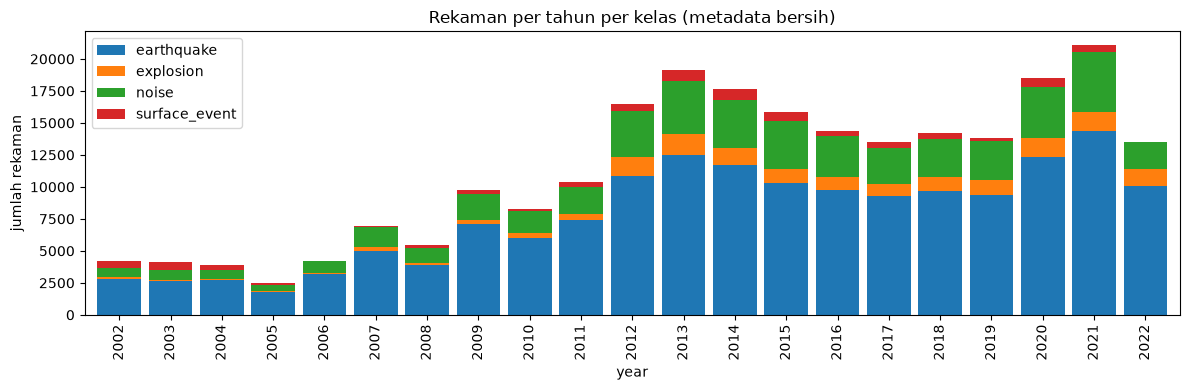

In [7]:
yearly = timed('groupBy year(trace_start_time), label', 'metadata',
               lambda: meta.groupBy(F.year('trace_start_time').alias('year')).pivot('label').count().orderBy('year').toPandas().set_index('year').fillna(0))
ax = yearly.plot(kind='bar', stacked=True, figsize=(12, 4), width=.85)
ax.set_ylabel('jumlah rekaman'); ax.set_title('Rekaman per tahun per kelas (metadata bersih)'); plt.tight_layout()
plt.savefig(f'{OUT_FIGS}/records_per_year.png', dpi=120); plt.show()

### 3c. Filter + window function: 5 event terbesar dan berapa stasiun yang merekamnya

In [8]:
w = Window.partitionBy('label').orderBy(F.desc('magnitude'))
top = timed('window: rank magnitude per label', 'metadata',
            lambda: events.filter("dataset='comcat'").withColumn('rank', F.row_number().over(w)).filter('rank <= 5')
                          .select('label', 'rank', 'event_id', 'origin_time', 'magnitude', 'depth_km', 'n_traces').toPandas())
top

[0.54 s] window: rank magnitude per label


,label,rank,event_id,origin_time,magnitude,depth_km,n_traces
0,earthquake,1,uw60507871,2013-02-27 22:25:44.340,5.10,4.182,4
1,earthquake,2,uw10763723,2009-01-30 13:25:03.760,4.86,62.240,9
2,earthquake,3,uw10583988,2003-04-25 10:02:12.710,4.80,50.513,7
3,earthquake,4,uw61114971,2015-12-30 07:39:29.310,4.79,52.420,7
4,earthquake,5,uw10831488,2011-11-18 13:09:00.980,4.72,11.168,2
5,explosion,1,uw10621928,2004-09-16 22:04:47.300,3.30,-0.745,2
6,explosion,2,uw60526356,2013-05-07 21:07:03.450,3.27,-0.268,2
7,explosion,3,uw61821341,2022-03-10 00:07:35.790,3.14,-0.600,3
8,explosion,4,uw61229642,2017-01-20 22:27:02.140,3.05,-0.710,1
9,explosion,5,uw61857197,2022-07-26 20:37:43.500,3.00,-0.600,2


### 3d. Shortcut risk: proporsi kelas per jaringan
Operasi groupBy + pivot. Ini menunjukkan kenapa `station_network_code` tidak boleh jadi fitur: jaringan **CC** (gunung api Cascades) mendominasi surface event.

In [9]:
net = timed('pivot network × label (% per label)', 'metadata',
            lambda: meta.groupBy('station_network_code').pivot('label').count().fillna(0).toPandas().set_index('station_network_code'))
(net / net.sum() * 100).round(1)

[0.16 s] pivot network × label (% per label)


,earthquake,explosion,noise,surface_event
station_network_code,,,,
HW,0.5,0.1,0.5,0.0
CN,2.7,9.4,3.3,0.0
UW,52.3,45.4,51.8,62.1
NV,0.0,0.0,0.0,0.0
UO,1.4,7.3,1.7,0.3
PB,22.6,23.7,21.8,5.1
US,1.8,1.8,1.9,0.0
CC,13.4,6.3,13.3,32.5
IU,0.0,0.0,0.0,0.0


## 4. Operasi untuk data unstructured (waveform = array)

Spark punya fungsi **higher-order** untuk kolom array (`transform`, `aggregate`, `slice`, `array_max`), sehingga perhitungan per sampel berjalan di JVM tanpa mengeluarkan data ke Python.

### 4a. Join waveform ⇄ metadata + fitur per trace
- **Join** di kunci `(dataset, trace_name)` → setiap waveform mendapat label.
- **Peak amplitude** komponen Z = `max(|z|)`.
- **Energi relatif**: rata-rata `z²` pada 10 detik setelah P dibanding 10 detik sebelum P (butuh `slice` pada array + indeks P dari metadata).

In [10]:
# broadcast: metadata kecil (±10 MB) dikirim ke setiap task → array waveform tidak perlu dipindah (shuffle) sama sekali
j = wf.join(F.broadcast(meta.select('dataset', 'trace_name', 'label', 'trace_P_arrival_sample', 'station_channel_code')), ['dataset', 'trace_name'])
feat = (j.withColumn('peak_z', F.array_max(F.transform('z', lambda x: F.abs(x))))
         .withColumn('p', F.coalesce('trace_P_arrival_sample', F.lit(7000)))   # noise: tanpa P → titik tengah window
         .withColumn('pre', F.expr('slice(z, greatest(p - 1000, 1), 1000)'))
         .withColumn('post', F.expr('slice(z, p + 1, 1000)'))
         .withColumn('snr_energy_db', F.expr('10 * log10(aggregate(post, 0D, (a, x) -> a + x*x) / greatest(aggregate(pre, 0D, (a, x) -> a + x*x), 1e-12))'))
         .select('dataset', 'label', 'station_channel_code', 'n_empty_components', 'peak_z', 'snr_energy_db'))
agg = timed('join + transform/slice/aggregate array per trace → groupBy label', 'waveforms + metadata',
            lambda: feat.filter('peak_z > 0').groupBy('label').agg(
                F.count('*').alias('traces'),
                F.round(F.expr('percentile_approx(log10(peak_z), 0.5)'), 2).alias('median_log10_peak_z'),
                F.round(F.expr('percentile_approx(snr_energy_db, 0.5)'), 1).alias('median_energy_ratio_db')).toPandas())
agg

[37.62 s] join + transform/slice/aggregate array per trace → groupBy label


,label,traces,median_log10_peak_z,median_energy_ratio_db
0,earthquake,159397,2.70,6.7
1,explosion,15931,2.69,6.8
2,surface_event,8912,3.14,8.0
3,noise,50227,2.16,0.0


Noise punya rasio energi ±0 dB (tidak ada sinyal yang "tiba"), sedangkan kelas event jauh di atas 0 → **sinyal waveform memang membawa informasi kelas**. Inilah dasar fitur A2 (bukan kolom metadata).

### 4b. Slice: menyeragamkan panjang window (persiapan A2)
Exotic 18,001 sampel dengan P di sampel 7000; ComCat/Noise 15,001. Satu operasi `slice` bisa memotong semua trace ke panjang yang sama, misalnya 60 detik sebelum P sampai 60 detik sesudah P = 12,000 sampel.

In [11]:
aligned = (j.withColumn('p', F.coalesce('trace_P_arrival_sample', F.lit(7500)))
            .withColumn('z_win', F.expr('slice(z, greatest(p - 6000 + 1, 1), 12000)'))
            .select('dataset', 'label', F.size('z').alias('len_before'), F.size('z_win').alias('len_after')))
timed('slice window 120 s → cek panjang', 'waveforms', lambda: aligned.groupBy('dataset', 'len_before', 'len_after').count().orderBy('dataset').toPandas())

[14.88 s] slice window 120 s → cek panjang


,dataset,len_before,len_after,count
0,comcat,15001,12000,178680
1,comcat,15001,11746,1
2,comcat,15001,11314,1
3,comcat,15001,11968,1
4,comcat,15001,11670,1
...,...,...,...,...
147,comcat,15001,11835,1
148,comcat,15001,10611,1
149,comcat,15001,11845,1
150,exotic,18001,12000,8912


Sebagian trace bisa lebih pendek dari 12,000 kalau P terlalu dekat ke awal/akhir rekaman. Aturan pemotongan final diputuskan di A2. Di sini yang penting: **operasinya bisa dilakukan langsung di Spark pada kolom array.**

## 5. Model graph: event ↔ stasiun (persiapan graph analytics A2)
- **Vertices** = event + stasiun
- **Edges** = rekaman (trace) yang menghubungkan 1 event dengan 1 stasiun

Semua diturunkan dari metadata dengan operasi DataFrame biasa. Di A2 DataFrame ini bisa langsung dipakai GraphFrames.

In [12]:
v_ev = events.select(F.concat_ws(':', F.lit('ev'), 'event_id').alias('id'), F.lit('event').alias('type'), 'label')
v_st = stations.select(F.concat_ws(':', F.lit('st'), 'station_network_code', 'station_code').alias('id'), F.lit('station').alias('type'), F.lit(None).cast('string').alias('label'))
vertices = v_ev.unionByName(v_st)
edges = (meta.filter('event_id IS NOT NULL')
             .select(F.concat_ws(':', F.lit('ev'), 'event_id').alias('src'),
                     F.concat_ws(':', F.lit('st'), 'station_network_code', 'station_code').alias('dst'), 'label', 'trace_name'))
deg_ev = edges.groupBy('src', 'label').agg(F.countDistinct('dst').alias('stations_per_event'))
deg_st = edges.groupBy('dst').agg(F.countDistinct('src').alias('events_per_station'))
g = timed('graph: vertices, edges, degree', 'metadata (graph)', lambda: pd.DataFrame([
    {'metric': 'vertices (event + station)', 'value': vertices.count()},
    {'metric': 'edges (event–station recordings)', 'value': edges.count()},
    {'metric': 'median stations per event', 'value': deg_ev.approxQuantile('stations_per_event', [0.5], 0)[0]},
    {'metric': 'max stations per event', 'value': deg_ev.agg(F.max('stations_per_event')).first()[0]},
    {'metric': 'median events per station', 'value': deg_st.approxQuantile('events_per_station', [0.5], 0)[0]},
    {'metric': 'max events per station', 'value': deg_st.agg(F.max('events_per_station')).first()[0]}]))
g

[1.60 s] graph: vertices, edges, degree


,metric,value
0,vertices (event + station),52092.0
1,edges (event–station recordings),187751.0
2,median stations per event,3.0
3,max stations per event,41.0
4,median events per station,68.0
5,max events per station,6658.0


In [13]:
deg_ev.groupBy('label').agg(F.round(F.avg('stations_per_event'), 1).alias('avg_stations_per_event')).show()

+-------------+----------------------+
|        label|avg_stations_per_event|
+-------------+----------------------+
|   earthquake|                   4.1|
|surface_event|                   1.6|
|    explosion|                   2.5|
+-------------+----------------------+



## 6. Simpan ringkasan untuk laporan

In [14]:
model = pd.DataFrame([
 ('Metadata (trace)', 'Structured', 'Relasional/tabular, tabel lebar (denormalized) berisi entitas Event, Station, Trace',
  '/datalake/processed/metadata/dataset=*/ (Parquet, Snappy)', '(dataset, trace_name)', 'filter, groupBy, pivot, window, join'),
 ('Waveform', 'Unstructured (array float64)', 'Array / wide-column: 1 baris per trace, kolom array e,n,z',
  '/datalake/processed/waveforms/dataset=*/ (Parquet nested array<double>)', '(dataset, trace_name)', 'join, transform, slice, aggregate, array_max'),
 ('Event–station network', 'Relasi (turunan)', 'Graph: vertices = event & station, edges = trace',
  'diturunkan dari metadata saat dibutuhkan', 'event_id, (network, station)', 'degree, konektivitas (A2: GraphFrames)'),
 ('Lineage & quality', 'Semi-structured', 'Dokumen JSON (key-value)', '/datalake/_lineage/, /datalake/quality/', 'file', 'baca/append dokumen'),
], columns=['data', 'format', 'data model', 'storage', 'key', 'operations'])
save_md(model, 'data_model', 'Model data per jenis data', ent.to_markdown(index=False))
ops = pd.DataFrame(timings)
save_md(ops, 'operations_timing', 'Contoh operasi Spark dan waktunya (local[*], 10 core)')
save_md(agg, 'waveform_features_by_class', 'Fitur sederhana dari waveform per kelas (median)')
save_md(g, 'graph_summary', 'Ringkasan model graph event–station')
ops

,operation,data,seconds
0,count semua trace (hanya metadata file Parquet...,waveforms,0.47
1,count trace_name distinct (baca 1 kolom kecil),waveforms,7.72
2,jumlah semua sampel z (harus membaca seluruh a...,waveforms,10.74
3,filter dataset=exotic → count (partition pruning),waveforms,0.06
4,"groupBy dataset, label → count",metadata,0.22
5,"groupBy year(trace_start_time), label",metadata,0.64
6,window: rank magnitude per label,metadata,0.54
7,pivot network × label (% per label),metadata,0.16
8,join + transform/slice/aggregate array per tra...,waveforms + metadata,37.62
9,slice window 120 s → cek panjang,waveforms,14.88


In [15]:
spark.stop()